<a href="https://colab.research.google.com/github/jessisam2007/24BAD049_24ADI006-DeepLearning/blob/main/Expt8_GAN_24BAD049.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EXPT NO: 8 — Generation of Synthetic Images Using a Generative Adversarial Network (GAN)
**Roll No:** 24BAD049  |  **Dataset:** MNIST  |  **Framework:** TensorFlow / Keras

**Aim:** To implement and train a GAN to generate synthetic images by training a Generator and a Discriminator in an adversarial learning framework.

## PART A: Dataset Preparation

Roll No: 24BAD049
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


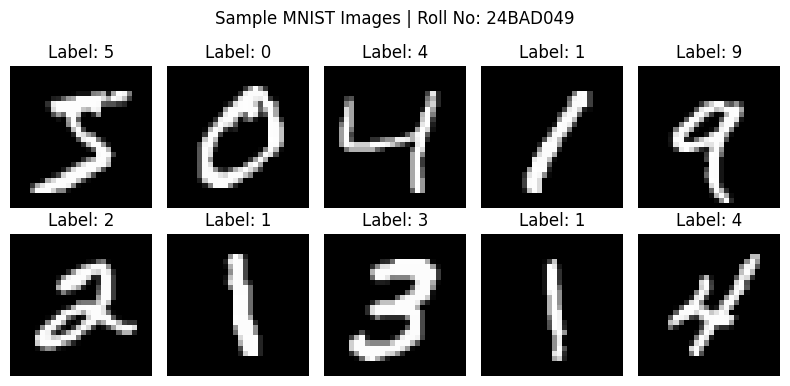

Training set shape : (60000, 28, 28)
Test set shape     : (10000, 28, 28)
Single image shape : (28, 28)
Data type          : uint8
Pixel range (raw)  : min = 0 , max = 255
Shape after reshape      : (60000, 28, 28, 1)
Pixel range (normalized) : min = -1.0 , max = 1.0
One batch of real images: (128, 28, 28, 1)
Number of batches per epoch: 469


In [1]:
# Roll No: 24BAD049

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

ROLL_NO = "24BAD049"
print("Roll No:", ROLL_NO)

# ---- 1. Load the MNIST dataset ----
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# ---- 2. Display sample images ----
plt.figure(figsize=(8, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.suptitle(f"Sample MNIST Images | Roll No: {ROLL_NO}")
plt.tight_layout()
plt.show()

# ---- 3. Explore image dimensions and pixel-value range ----
print("Training set shape :", x_train.shape)
print("Test set shape     :", x_test.shape)
print("Single image shape :", x_train[0].shape)
print("Data type          :", x_train.dtype)
print("Pixel range (raw)  : min =", x_train.min(), ", max =", x_train.max())

# ---- 4. Normalize and reshape for the GAN ----
# Scale pixels from [0, 255] to [-1, 1] (matches the Generator's tanh output)
x_train = (x_train.astype("float32") - 127.5) / 127.5
# Add the channel dimension: (60000, 28, 28) -> (60000, 28, 28, 1)
x_train = np.expand_dims(x_train, axis=-1)

print("Shape after reshape      :", x_train.shape)
print("Pixel range (normalized) : min =", x_train.min(), ", max =", x_train.max())

# ---- 5. Prepare batches of real images ----
BUFFER_SIZE = x_train.shape[0]
BATCH_SIZE = 128

train_dataset = (tf.data.Dataset.from_tensor_slices(x_train)
                 .shuffle(BUFFER_SIZE)
                 .batch(BATCH_SIZE)
                 .prefetch(tf.data.AUTOTUNE))

for real_batch in train_dataset.take(1):
    print("One batch of real images:", real_batch.shape)
print("Number of batches per epoch:", len(train_dataset))

## PART B: Implementing the Generator and Discriminator

In [2]:
# Roll No: 24BAD049

from tensorflow.keras import layers

print("Roll No:", ROLL_NO)

LATENT_DIM = 100   # size of the random noise vector

# ---- 1. Generator: noise vector -> 28x28x1 synthetic image ----
def build_generator():
    model = keras.Sequential([
        keras.Input(shape=(LATENT_DIM,)),
        layers.Dense(7 * 7 * 128, use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),
        layers.Reshape((7, 7, 128)),
        # 7x7 -> 14x14
        layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),
        # 14x14 -> 28x28 ; tanh gives output in [-1, 1]
        layers.Conv2DTranspose(1, 4, strides=2, padding="same", activation="tanh"),
    ], name="Generator")
    return model

# ---- 2. Discriminator: image -> probability of being real ----
def build_discriminator():
    model = keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        layers.Conv2D(64, 4, strides=2, padding="same"),
        layers.LeakyReLU(0.2),
        layers.Dropout(0.3),
        layers.Conv2D(128, 4, strides=2, padding="same"),
        layers.LeakyReLU(0.2),
        layers.Dropout(0.3),
        layers.Flatten(),
        layers.Dense(1, activation="sigmoid"),   # 1 = real, 0 = fake
    ], name="Discriminator")
    return model

generator = build_generator()
discriminator = build_discriminator()

# ---- 3. Loss function and optimizers ----
# Binary cross-entropy is used for both models
cross_entropy = keras.losses.BinaryCrossentropy()
generator_optimizer = keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5)
discriminator_optimizer = keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)    # real -> 1
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)   # fake -> 0
    return real_loss + fake_loss

def generator_loss(fake_output):
    # Generator wants the Discriminator to label its fakes as real (1)
    return cross_entropy(tf.ones_like(fake_output), fake_output)

# ---- 4. Combine Generator and Discriminator to construct the GAN ----
z_input = keras.Input(shape=(LATENT_DIM,), name="noise_input")
generated_image = generator(z_input)
validity = discriminator(generated_image)
gan = keras.Model(z_input, validity, name="GAN")

# ---- 5. Display model summaries ----
generator.summary()
discriminator.summary()
gan.summary()

Roll No: 24BAD049


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 784,641 (2.99 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 12,672 (49.50 KB)

... (6 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ noise_input (InputLayer)        │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Generator (Sequential)          │ (None, 28, 28, 1)      │       784,641 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       138,561 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 923,202 (3.52 MB)

 Trainable params: 910,530 (3.47 MB)

 Non-trainable params: 12,672 (49.50 KB)

## PART C: GAN Training and Performance Monitoring

Roll No: 24BAD049
Epoch 01/30 | D Loss: 1.1506 | G Loss: 0.8261 | Time: 16.5s


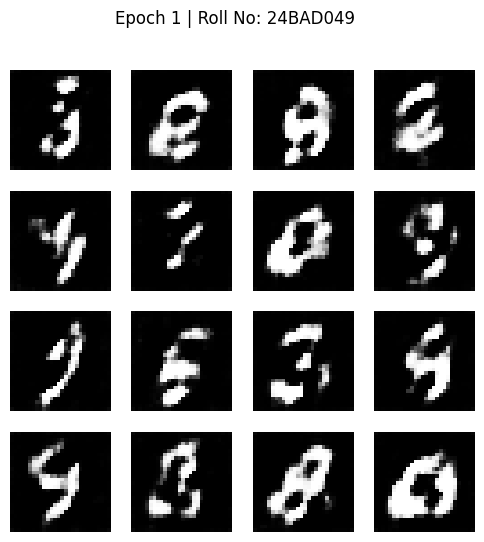

Epoch 02/30 | D Loss: 1.2454 | G Loss: 0.8390 | Time: 7.3s
Epoch 03/30 | D Loss: 1.1474 | G Loss: 0.9502 | Time: 7.3s
Epoch 04/30 | D Loss: 1.1928 | G Loss: 0.9373 | Time: 7.3s
Epoch 05/30 | D Loss: 1.2371 | G Loss: 0.8959 | Time: 7.3s


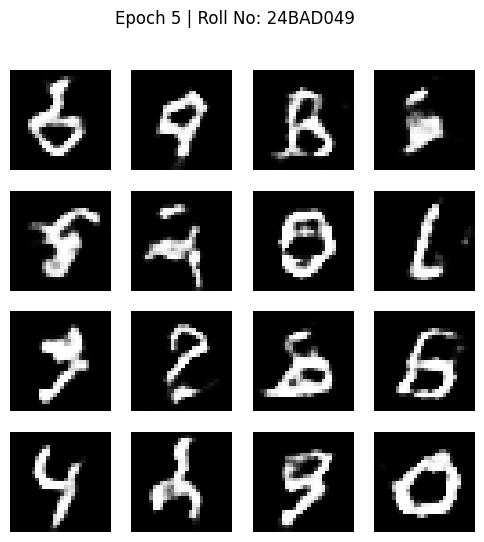

Epoch 06/30 | D Loss: 1.2613 | G Loss: 0.8628 | Time: 8.8s
Epoch 07/30 | D Loss: 1.2746 | G Loss: 0.8443 | Time: 7.4s
Epoch 08/30 | D Loss: 1.2786 | G Loss: 0.8380 | Time: 7.3s
Epoch 09/30 | D Loss: 1.2767 | G Loss: 0.8407 | Time: 7.3s
Epoch 10/30 | D Loss: 1.2682 | G Loss: 0.8464 | Time: 7.4s


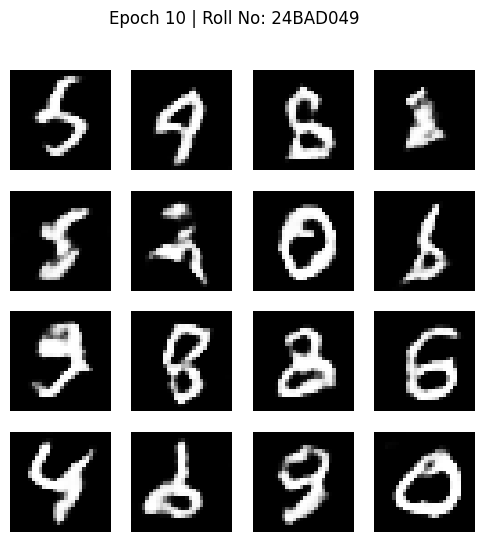

Epoch 11/30 | D Loss: 1.2614 | G Loss: 0.8539 | Time: 7.5s
Epoch 12/30 | D Loss: 1.2504 | G Loss: 0.8633 | Time: 7.4s
Epoch 13/30 | D Loss: 1.2445 | G Loss: 0.8768 | Time: 7.4s
Epoch 14/30 | D Loss: 1.2423 | G Loss: 0.8841 | Time: 7.5s
Epoch 15/30 | D Loss: 1.2356 | G Loss: 0.8921 | Time: 7.5s


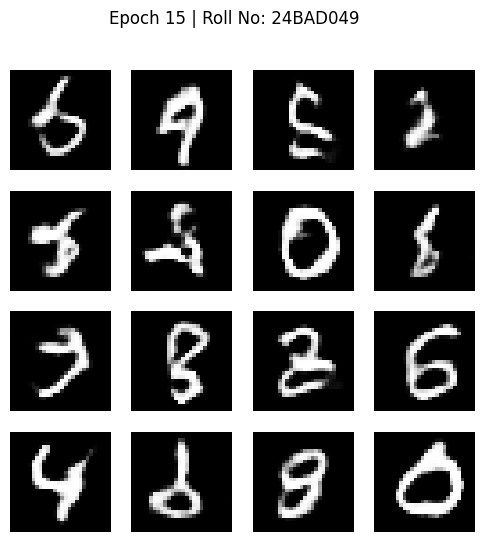

Epoch 16/30 | D Loss: 1.2321 | G Loss: 0.8981 | Time: 7.3s
Epoch 17/30 | D Loss: 1.2284 | G Loss: 0.9072 | Time: 7.6s
Epoch 18/30 | D Loss: 1.2300 | G Loss: 0.9097 | Time: 7.4s
Epoch 19/30 | D Loss: 1.2270 | G Loss: 0.9122 | Time: 7.6s
Epoch 20/30 | D Loss: 1.2228 | G Loss: 0.9237 | Time: 7.6s


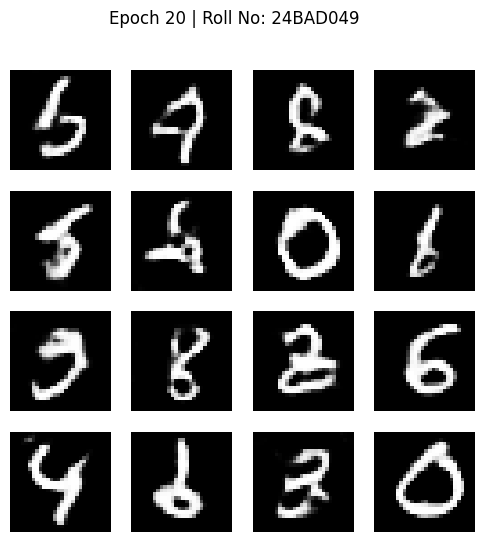

Epoch 21/30 | D Loss: 1.2243 | G Loss: 0.9205 | Time: 7.5s
Epoch 22/30 | D Loss: 1.2226 | G Loss: 0.9274 | Time: 7.6s
Epoch 23/30 | D Loss: 1.2182 | G Loss: 0.9274 | Time: 7.5s
Epoch 24/30 | D Loss: 1.2191 | G Loss: 0.9365 | Time: 7.6s
Epoch 25/30 | D Loss: 1.2197 | G Loss: 0.9328 | Time: 7.7s


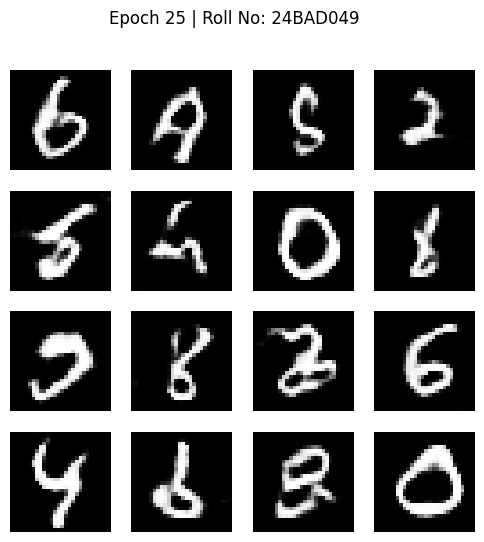

Epoch 26/30 | D Loss: 1.2201 | G Loss: 0.9402 | Time: 7.5s
Epoch 27/30 | D Loss: 1.2180 | G Loss: 0.9358 | Time: 7.7s
Epoch 28/30 | D Loss: 1.2144 | G Loss: 0.9421 | Time: 7.6s
Epoch 29/30 | D Loss: 1.2124 | G Loss: 0.9475 | Time: 7.7s
Epoch 30/30 | D Loss: 1.2150 | G Loss: 0.9464 | Time: 7.7s


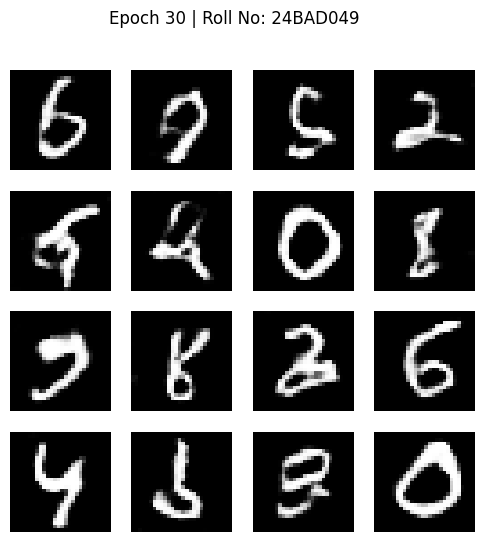

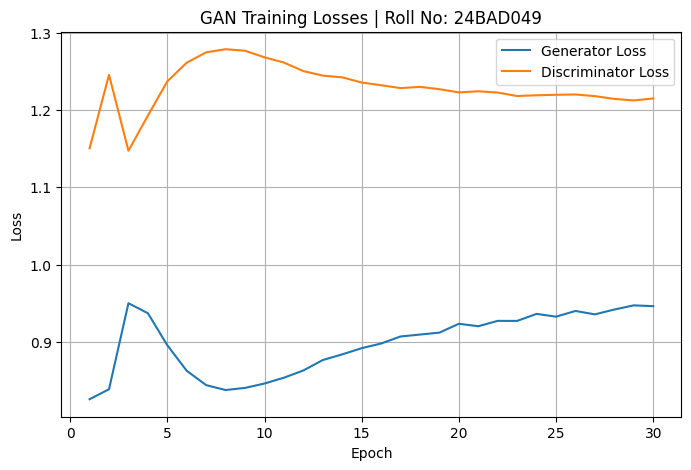

In [3]:
# Roll No: 24BAD049

import time

print("Roll No:", ROLL_NO)

EPOCHS = 30
NUM_EXAMPLES = 16
SAMPLE_INTERVAL = 5   # show generated images every 5 epochs

# Fixed noise so progress can be compared across epochs
seed_noise = tf.random.normal([NUM_EXAMPLES, LATENT_DIM])

# ---- 1. One training step: train Discriminator, then Generator ----
@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal([batch_size, LATENT_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)   # real images
        fake_output = discriminator(fake_images, training=True)   # generated images

        d_loss = discriminator_loss(real_output, fake_output)
        g_loss = generator_loss(fake_output)

    # Update Discriminator weights using real + generated images
    d_grads = disc_tape.gradient(d_loss, discriminator.trainable_variables)
    discriminator_optimizer.apply_gradients(zip(d_grads, discriminator.trainable_variables))

    # Update Generator weights so that its images fool the Discriminator
    g_grads = gen_tape.gradient(g_loss, generator.trainable_variables)
    generator_optimizer.apply_gradients(zip(g_grads, generator.trainable_variables))

    return d_loss, g_loss

# ---- 2. Display sample generated images during training ----
def show_generated_images(epoch):
    preds = generator(seed_noise, training=False)
    plt.figure(figsize=(6, 6))
    for i in range(NUM_EXAMPLES):
        plt.subplot(4, 4, i + 1)
        plt.imshow(preds[i, :, :, 0] * 127.5 + 127.5, cmap="gray")
        plt.axis("off")
    plt.suptitle(f"Epoch {epoch} | Roll No: {ROLL_NO}")
    plt.show()

# ---- 3. Training loop (alternating Discriminator / Generator updates) ----
g_losses, d_losses = [], []

for epoch in range(1, EPOCHS + 1):
    start = time.time()
    d_epoch, g_epoch = [], []

    for image_batch in train_dataset:
        d_l, g_l = train_step(image_batch)
        d_epoch.append(float(d_l))
        g_epoch.append(float(g_l))

    # Record the average loss of this epoch
    d_losses.append(np.mean(d_epoch))
    g_losses.append(np.mean(g_epoch))

    print(f"Epoch {epoch:02d}/{EPOCHS} | D Loss: {d_losses[-1]:.4f} | "
          f"G Loss: {g_losses[-1]:.4f} | Time: {time.time() - start:.1f}s")

    if epoch == 1 or epoch % SAMPLE_INTERVAL == 0:
        show_generated_images(epoch)

# ---- 4. Plot Generator and Discriminator losses ----
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), g_losses, label="Generator Loss")
plt.plot(range(1, EPOCHS + 1), d_losses, label="Discriminator Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"GAN Training Losses | Roll No: {ROLL_NO}")
plt.legend()
plt.grid(True)
plt.show()

## PART D: Generating and Comparing Synthetic Images

Roll No: 24BAD049
Latent vectors shape: (16, 100)
Latent mean = -0.033, std = 1.002


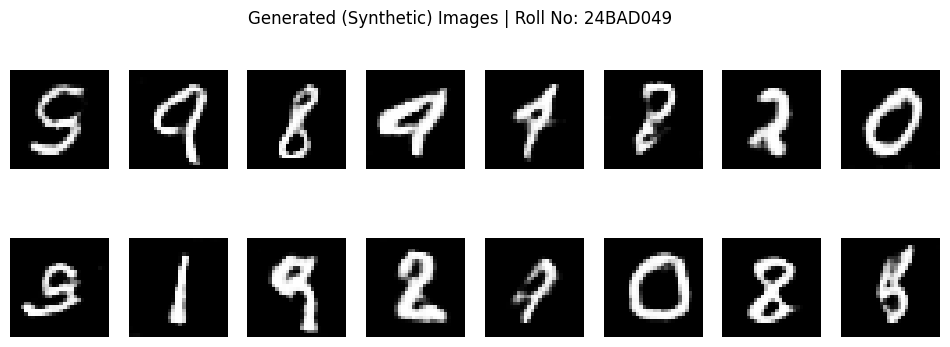

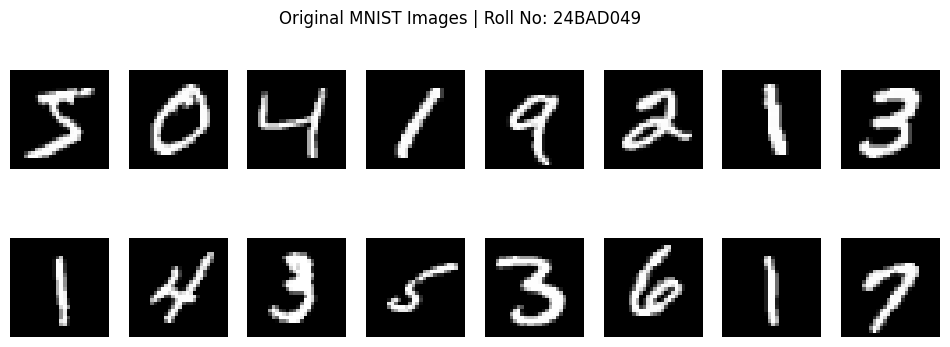

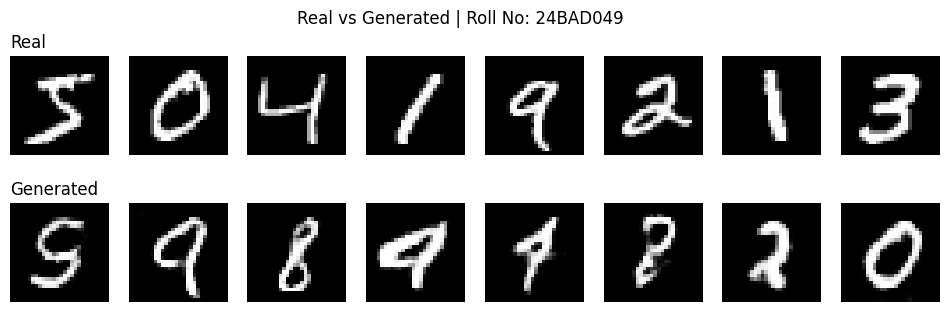

In [4]:
# Roll No: 24BAD049

print("Roll No:", ROLL_NO)

NUM_IMAGES = 16

# ---- 1. Latent-space representations (random noise vectors) ----
# In a GAN, the latent space is the space of noise vectors fed to the Generator
latent_vectors = tf.random.normal([NUM_IMAGES, LATENT_DIM])
print("Latent vectors shape:", latent_vectors.shape)
print("Latent mean = %.3f, std = %.3f" % (float(tf.reduce_mean(latent_vectors)),
                                          float(tf.math.reduce_std(latent_vectors))))

# ---- 2. Generate synthetic images using the trained Generator ----
generated_images = generator(latent_vectors, training=False).numpy()
generated_images = generated_images * 127.5 + 127.5     # rescale [-1, 1] -> [0, 255]

# ---- 3. Pick original dataset samples for comparison ----
real_images = x_train[:NUM_IMAGES] * 127.5 + 127.5

# ---- 4. Display generated images vs original images ----
fig, axes = plt.subplots(2, NUM_IMAGES // 2, figsize=(12, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(generated_images[i, :, :, 0], cmap="gray")
    ax.axis("off")
fig.suptitle(f"Generated (Synthetic) Images | Roll No: {ROLL_NO}")
plt.show()

fig, axes = plt.subplots(2, NUM_IMAGES // 2, figsize=(12, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(real_images[i, :, :, 0], cmap="gray")
    ax.axis("off")
fig.suptitle(f"Original MNIST Images | Roll No: {ROLL_NO}")
plt.show()

# ---- 5. Side-by-side comparison (top row: real, bottom row: generated) ----
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i in range(8):
    axes[0, i].imshow(real_images[i, :, :, 0], cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].imshow(generated_images[i, :, :, 0], cmap="gray")
    axes[1, i].axis("off")
axes[0, 0].set_title("Real", loc="left")
axes[1, 0].set_title("Generated", loc="left")
fig.suptitle(f"Real vs Generated | Roll No: {ROLL_NO}")
plt.show()

